# Q1

In [1]:
# module imports
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_svmlight_file
import numpy as np

In [2]:
# load data and split into train-test

X, y = load_svmlight_file('sonar/sonar_scale.txt')

# density
X = X.toarray()

train_idx = np.loadtxt('sonar/sonar-scale-train-indices.txt', dtype=int) - 1
test_idx = np.loadtxt('sonar/sonar-scale-test-indices.txt', dtype=int) - 1

X_train = X[train_idx]
X_test = X[test_idx]
y_train = y[train_idx]
y_test = y[test_idx]

In [3]:
# preprocess data
sc = StandardScaler()
X_train_std = sc.fit_transform(X_train)
X_test_std = sc.transform(X_test)

In [4]:
# set up gridsearch CV
grid = {"C": [0.1, 1, 10, 100, 1000]}

model = LogisticRegression(penalty='l2', solver='liblinear')

search = GridSearchCV(estimator=model, param_grid=grid, cv=5, return_train_score=True,)

In [5]:
# fit model
search.fit(X_train_std, y_train)
best_model = search.best_estimator_

/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penal

In [6]:
# load results from search
import pandas as pd
results_df = pd.DataFrame(search.cv_results_)


In [7]:
# report average train scores
1 - results_df['mean_train_score']

0    0.075000
1    0.016667
2    0.000000
3    0.000000
4    0.000000
Name: mean_train_score, dtype: float64

In [8]:
# report average test scores
1 - results_df['mean_test_score']

0    0.360000
1    0.366667
2    0.353333
3    0.346667
4    0.366667
Name: mean_test_score, dtype: float64

In [9]:
# report best C
search.best_params_

{'C': 100}

In [10]:
# calculate testing error on best C
from sklearn.metrics import accuracy_score
y_pred = best_model.predict(X_test_std)
print("error rate:", 1 - accuracy_score(y_test, y_pred))

error rate: 0.2586206896551724


# Q2

In [11]:
# try same experiment with different libsvm kernels
from sklearn.svm import SVC

grid = {
    "kernel": ["linear", "poly", "rbf"],
    "C": [0.1, 1, 10, 100, 1000]
}

search = GridSearchCV(estimator=SVC(), param_grid=grid, cv=5, return_train_score=True,)

In [12]:
# fit model
search.fit(X_train_std, y_train)
best_model = search.best_estimator_

In [13]:
# load results from search
import pandas as pd
results_df = pd.DataFrame(search.cv_results_)


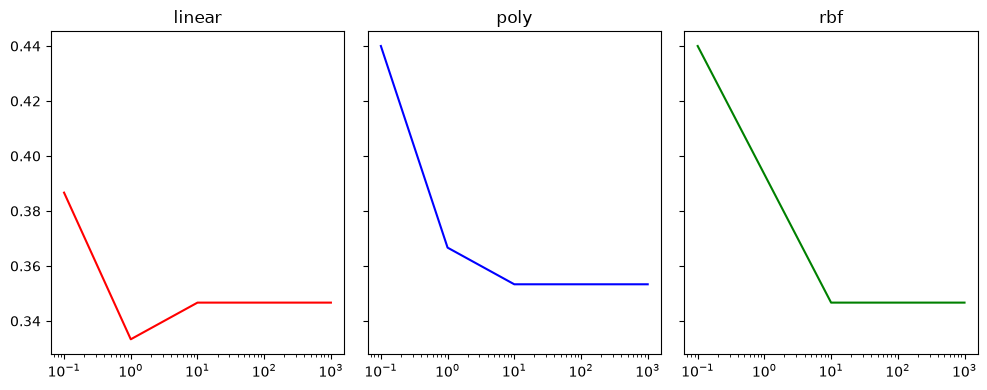

In [14]:
# report errors per kernel across regularization strengths
import matplotlib.pyplot as plt

fig, axes = plt.subplots(nrows=1, ncols=3, sharex=True, sharey=True, figsize=(10,4))

axes = axes.flatten()

kernels = ["linear", "poly", "rbf"]
colors = ["red", "blue", "green"]

for i, kernel in enumerate(kernels):
    ax = axes[i]
    kernel_df = results_df[results_df["param_kernel"] == kernel]
    err = 1 - kernel_df["mean_test_score"]
    x = kernel_df['param_C']
    ax.plot(x, err, color=colors[i])
    ax.set_title(kernel)
    ax.set_xscale('log')

#plt.title("mean test error across kernels")
plt.tight_layout()
plt.show()

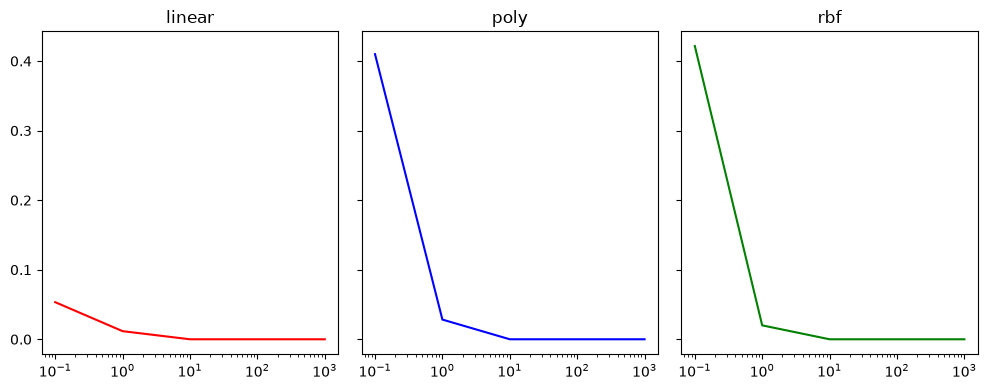

In [15]:
# report errors per kernel across regularization strengths
import matplotlib.pyplot as plt

fig, axes = plt.subplots(nrows=1, ncols=3, sharex=True, sharey=True, figsize=(10,4))

axes = axes.flatten()

kernels = ["linear", "poly", "rbf"]
colors = ["red", "blue", "green"]

for i, kernel in enumerate(kernels):
    ax = axes[i]
    kernel_df = results_df[results_df["param_kernel"] == kernel]
    err = 1 - kernel_df["mean_train_score"]
    x = kernel_df['param_C']
    ax.plot(x, err, color=colors[i])
    ax.set_title(kernel)
    ax.set_xscale('log')

#plt.title("mean test error across kernels")
plt.tight_layout()
plt.show()

In [16]:
# report best fit
search.best_params_

{'C': 1, 'kernel': 'linear'}

In [17]:
# calculate testing error on best C
from sklearn.metrics import accuracy_score
y_pred = best_model.predict(X_test_std)
print("error rate:", 1 - accuracy_score(y_test, y_pred))

error rate: 0.2068965517241379


# Q3

In [141]:
# load data
from ResNet.DataReader import load_data
data_path = '/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/cifar-10'
x_train, y_train, x_test, y_test = load_data(data_path)

In [142]:
# create val split for hyperparam selection (lr)
from sklearn.model_selection import train_test_split
x_tune, x_val, y_tune, y_val = train_test_split(x_train, y_train, train_size=.9)


In [95]:
# train models for each lr
from ResNet.Model import Config, Cifar

for i, lr in enumerate([0.003, 0.01, 0.03]):
    tune_config = Config(save_interval=10, max_epochs=100, lr=lr, config_id=i)
    modeler = Cifar(tune_config)
    modeler.train(x_tune, y_tune, tune_config.max_epochs)

### Training... ###
Epoch 1 Loss 1.484712 Duration 61.912 seconds.
Epoch 2 Loss 1.278486 Duration 60.121 seconds.
Epoch 3 Loss 1.073004 Duration 58.528 seconds.
Epoch 4 Loss 1.001718 Duration 58.554 seconds.
Epoch 5 Loss 0.868371 Duration 58.311 seconds.
Epoch 6 Loss 0.652639 Duration 58.280 seconds.
Epoch 7 Loss 0.965496 Duration 57.792 seconds.
Epoch 8 Loss 0.650872 Duration 56.833 seconds.
Epoch 9 Loss 0.745557 Duration 56.360 seconds.
Epoch 10 Loss 0.731628 Duration 55.222 seconds.
Checkpoint has been created.
Epoch 11 Loss 0.482029 Duration 53.697 seconds.
Epoch 12 Loss 0.525409 Duration 55.348 seconds.
Epoch 13 Loss 0.819879 Duration 53.574 seconds.
Epoch 14 Loss 0.729463 Duration 53.454 seconds.
Epoch 15 Loss 0.512320 Duration 53.606 seconds.
Epoch 16 Loss 0.452938 Duration 54.724 seconds.
Epoch 17 Loss 0.671128 Duration 53.786 seconds.
Epoch 18 Loss 0.444834 Duration 53.466 seconds.
Epoch 19 Loss 0.623539 Duration 54.006 seconds.
Epoch 20 Loss 0.635375 Duration 54.687 seconds.


In [143]:
# run validation per model - pick one w/ best accuracy
best_acc = 0
best_lr = None
for i, lr in enumerate([0.003, 0.01, 0.03]):
    tune_config = Config(save_interval=10, max_epochs=100, lr=lr, config_id=i)
    modeler = Cifar(tune_config)
    accs, _, _, _ = modeler.test_or_validate(x_val, y_val, [100])
    acc = accs[0]
    if acc > best_acc:
        best_lr = lr
        best_acc = acc


### Test or Validation ###
Restored model parameters from checkpoints/0/model-100.ckpt


/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:206: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  if self.config.dataset == 'cifar':


Test accuracy: 0.9444
ROC_AUC: 0.9977
PR_AUC: 0.9844
### Test or Validation ###
Restored model parameters from checkpoints/1/model-100.ckpt


/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:206: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  if self.config.dataset == 'cifar':


Test accuracy: 0.8636
ROC_AUC: 0.9894
PR_AUC: 0.9348
### Test or Validation ###
Restored model parameters from checkpoints/2/model-100.ckpt
Test accuracy: 0.7230
ROC_AUC: 0.9616
PR_AUC: 0.8055


/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:206: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  if self.config.dataset == 'cifar':


In [144]:
# initialize model - original
from ResNet.Model import Config, Cifar

std_config = Config(save_interval=10, max_epochs=100, lr=best_lr, config_id=3)
modeler = Cifar(std_config)

In [145]:
# train model
std_losses = modeler.train(x_train, y_train, std_config.max_epochs)

### Training... ###
Epoch 1 Loss 1.486163 Duration 70.316 seconds.
Epoch 2 Loss 1.066971 Duration 61.745 seconds.
Epoch 3 Loss 0.929414 Duration 62.543 seconds.
Epoch 4 Loss 1.100836 Duration 61.017 seconds.
Epoch 5 Loss 0.871912 Duration 59.956 seconds.
Epoch 6 Loss 0.834326 Duration 61.469 seconds.
Epoch 7 Loss 0.850811 Duration 60.474 seconds.
Epoch 8 Loss 0.784790 Duration 59.562 seconds.
Epoch 9 Loss 0.808744 Duration 59.464 seconds.
Epoch 10 Loss 0.593196 Duration 59.519 seconds.
Checkpoint has been created.
Epoch 11 Loss 0.810904 Duration 60.062 seconds.
Epoch 12 Loss 0.569140 Duration 59.766 seconds.
Epoch 13 Loss 0.543777 Duration 59.425 seconds.
Epoch 14 Loss 0.611730 Duration 59.437 seconds.
Epoch 15 Loss 0.614795 Duration 59.476 seconds.
Epoch 16 Loss 0.700651 Duration 59.448 seconds.
Epoch 17 Loss 0.521724 Duration 59.517 seconds.
Epoch 18 Loss 0.568551 Duration 61.140 seconds.
Epoch 19 Loss 0.772286 Duration 61.875 seconds.
Epoch 20 Loss 0.385008 Duration 61.766 seconds.


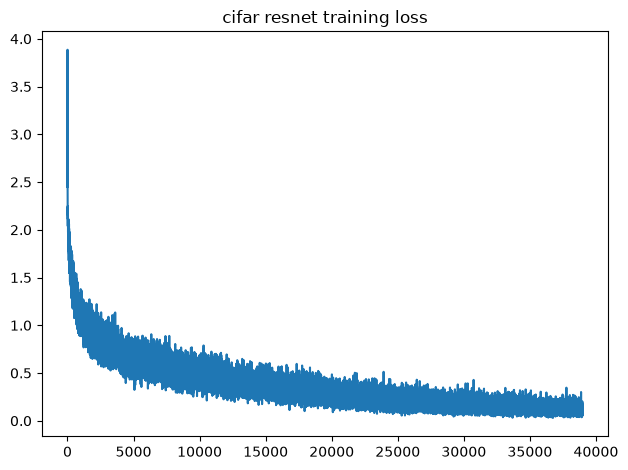

In [146]:
# plot training loss
import matplotlib.pyplot as plt

plt.plot(std_losses.ravel())
plt.title("cifar resnet training loss")
plt.tight_layout()
plt.savefig("figures/cifar_resnet_train_loss.png")
plt.show()

In [111]:
# run test stats
std_config = Config(save_interval=10, max_epochs=100, lr=best_lr, config_id=3)
modeler = Cifar(std_config)
accs, _, _, losses = modeler.test_or_validate(x_test, y_test, [i * 10 for i in range(1, 11)])


### Test or Validation ###
Restored model parameters from checkpoints/3/model-10.ckpt


/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:206: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  y_proba = F.softmax(y_proba)


Test accuracy: 0.7197
ROC_AUC: 0.9603
PR_AUC: 0.8109
Restored model parameters from checkpoints/3/model-20.ckpt


/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:206: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  y_proba = F.softmax(y_proba)


Test accuracy: 0.7635
ROC_AUC: 0.9728
PR_AUC: 0.8601
Restored model parameters from checkpoints/3/model-30.ckpt


/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:206: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  y_proba = F.softmax(y_proba)


... (10 outputs left out)

Test accuracy: 0.8360
ROC_AUC: 0.9848
PR_AUC: 0.9157
Restored model parameters from checkpoints/3/model-90.ckpt


/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:206: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  y_proba = F.softmax(y_proba)


Test accuracy: 0.8379
ROC_AUC: 0.9851
PR_AUC: 0.9163
Restored model parameters from checkpoints/3/model-100.ckpt
Test accuracy: 0.8427
ROC_AUC: 0.9853
PR_AUC: 0.9188


/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:206: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  y_proba = F.softmax(y_proba)


final test acc: 0.8427


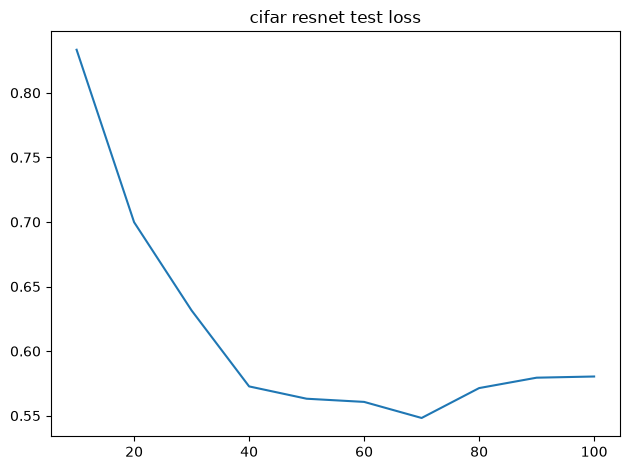

In [112]:
acc = accs[-1]
print("final test acc:", acc)
plt.plot([i * 10 for i in range(1, 11)], losses)
plt.title("cifar resnet test loss")
plt.tight_layout()
plt.savefig("figures/cifar_resnet_test_loss.png")
plt.show()

In [147]:
# inititlize model - batchnorm ablated
batch_config = Config(save_interval=10, norm_on=False, max_epochs=100, lr=best_lr, config_id=4)
modeler = Cifar(batch_config)

In [148]:
batch_losses = modeler.train(x_train, y_train, batch_config.max_epochs)

### Training... ###
Epoch 1 Loss 1.590961 Duration 58.201 seconds.
Epoch 2 Loss 1.496575 Duration 57.622 seconds.
Epoch 3 Loss 1.279275 Duration 57.539 seconds.
Epoch 4 Loss 1.243233 Duration 57.582 seconds.
Epoch 5 Loss 1.019949 Duration 57.521 seconds.
Epoch 6 Loss 0.993695 Duration 57.519 seconds.
Epoch 7 Loss 1.069742 Duration 57.521 seconds.
Epoch 8 Loss 0.957054 Duration 57.554 seconds.
Epoch 9 Loss 1.240880 Duration 57.747 seconds.
Epoch 10 Loss 0.904133 Duration 57.688 seconds.
Checkpoint has been created.
Epoch 11 Loss 0.934470 Duration 57.566 seconds.
Epoch 12 Loss 0.815878 Duration 57.973 seconds.
Epoch 13 Loss 0.987104 Duration 57.790 seconds.
Epoch 14 Loss 0.973183 Duration 57.538 seconds.
Epoch 15 Loss 0.683154 Duration 57.594 seconds.
Epoch 16 Loss 0.797528 Duration 57.553 seconds.
Epoch 17 Loss 0.865636 Duration 57.680 seconds.
Epoch 18 Loss 0.789544 Duration 57.561 seconds.
Epoch 19 Loss 0.709546 Duration 57.783 seconds.
Epoch 20 Loss 0.742616 Duration 57.969 seconds.


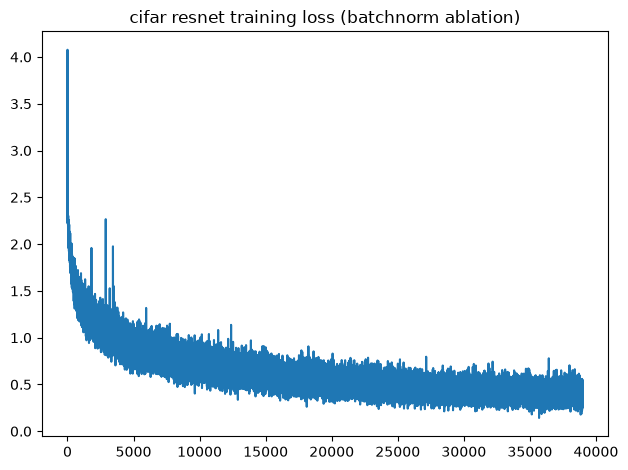

In [149]:
# plot loss curves
# plot training loss
import matplotlib.pyplot as plt

plt.plot(batch_losses.ravel())
plt.title("cifar resnet training loss (batchnorm ablation)")
plt.tight_layout()
plt.savefig("figures/cifar_resnet_batch_ablation_train_loss.png")
plt.show()

In [113]:
# run test stats
batch_config = Config(save_interval=10, norm_on=False, max_epochs=100, lr=best_lr, config_id=4)
modeler = Cifar(batch_config)
accs, _, _, losses = modeler.test_or_validate(x_test, y_test, [i * 10 for i in range(1, 11)])


### Test or Validation ###
Restored model parameters from checkpoints/4/model-10.ckpt


/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:206: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  y_proba = F.softmax(y_proba)


Test accuracy: 0.5934
ROC_AUC: 0.9189
PR_AUC: 0.6626
Restored model parameters from checkpoints/4/model-20.ckpt


/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:206: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  y_proba = F.softmax(y_proba)


Test accuracy: 0.6714
ROC_AUC: 0.9482
PR_AUC: 0.7619
Restored model parameters from checkpoints/4/model-30.ckpt


/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:206: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  y_proba = F.softmax(y_proba)


... (10 outputs left out)

Test accuracy: 0.7982
ROC_AUC: 0.9773
PR_AUC: 0.8803
Restored model parameters from checkpoints/4/model-90.ckpt


/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:206: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  y_proba = F.softmax(y_proba)


Test accuracy: 0.7978
ROC_AUC: 0.9774
PR_AUC: 0.8808
Restored model parameters from checkpoints/4/model-100.ckpt
Test accuracy: 0.8025
ROC_AUC: 0.9782
PR_AUC: 0.8839


/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:206: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  y_proba = F.softmax(y_proba)


final test acc: 0.8025


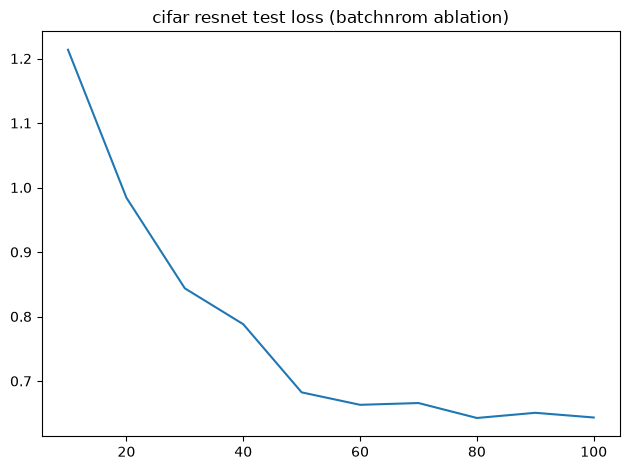

In [114]:
acc = accs[-1]
print("final test acc:", acc)
plt.plot([i * 10 for i in range(1, 11)], losses)
plt.title("cifar resnet test loss (batchnrom ablation)")
plt.tight_layout()
plt.savefig("figures/cifar_resnet_batch_ablation_test_loss.png")
plt.show()

In [150]:
# initial model - residual connections ablated
res_config = Config(save_interval=10, res_on=False, max_epochs=100, lr=best_lr, config_id=5)
modeler = Cifar(res_config)

In [152]:
res_losses = modeler.train(x_train, y_train, res_config.max_epochs)

### Training... ###
Epoch 1 Loss 0.749913 Duration 68.413 seconds.
Epoch 2 Loss 0.565327 Duration 71.168 seconds.
Epoch 3 Loss 0.646194 Duration 69.788 seconds.
Epoch 4 Loss 0.558007 Duration 66.029 seconds.
Epoch 5 Loss 0.712381 Duration 68.854 seconds.
Epoch 6 Loss 0.762921 Duration 68.069 seconds.
Epoch 7 Loss 0.580136 Duration 60.011 seconds.
Epoch 8 Loss 0.773776 Duration 60.911 seconds.
Epoch 9 Loss 0.479751 Duration 60.169 seconds.
Epoch 10 Loss 0.717650 Duration 59.808 seconds.
Checkpoint has been created.
Epoch 11 Loss 0.432894 Duration 59.699 seconds.
Epoch 12 Loss 0.628049 Duration 59.384 seconds.
Epoch 13 Loss 0.523973 Duration 59.265 seconds.
Epoch 14 Loss 0.604544 Duration 59.439 seconds.
Epoch 15 Loss 0.623631 Duration 59.187 seconds.
Epoch 16 Loss 0.506480 Duration 59.833 seconds.
Epoch 17 Loss 0.583799 Duration 58.824 seconds.
Epoch 18 Loss 0.597076 Duration 58.307 seconds.
Epoch 19 Loss 0.658210 Duration 58.545 seconds.
Epoch 20 Loss 0.386319 Duration 59.320 seconds.


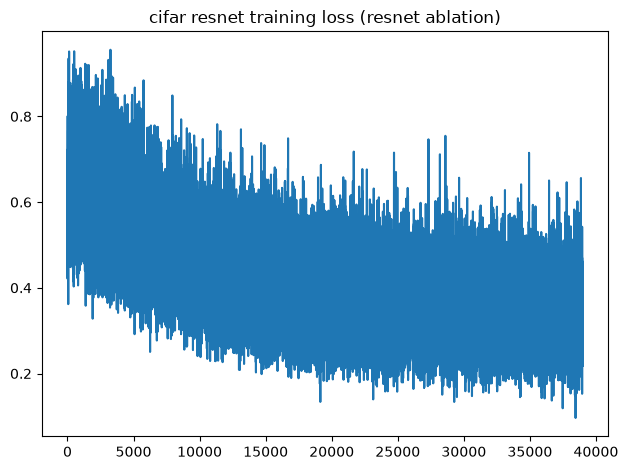

In [153]:
# plot loss curves
import matplotlib.pyplot as plt

plt.plot(res_losses.ravel())
plt.title("cifar resnet training loss (resnet ablation)")
plt.tight_layout()
plt.savefig("figures/cifar_resnet_batch_ablation_train_loss.png")
plt.show()

In [154]:
# run test stats
res_config = Config(save_interval=10, res_on=False, max_epochs=100, lr=best_lr, config_id=5)
modeler = Cifar(res_config)
accs, _, _, losses = modeler.test_or_validate(x_test, y_test, [i * 10 for i in range(1, 11)])


### Test or Validation ###
Restored model parameters from checkpoints/5/model-10.ckpt


/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:206: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  if self.config.dataset == 'cifar':


Test accuracy: 0.7653
ROC_AUC: 0.9634
PR_AUC: 0.8443
Restored model parameters from checkpoints/5/model-20.ckpt


/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:206: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  if self.config.dataset == 'cifar':


Test accuracy: 0.7855
ROC_AUC: 0.9692
PR_AUC: 0.8619
Restored model parameters from checkpoints/5/model-30.ckpt


/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:206: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  if self.config.dataset == 'cifar':


... (10 outputs left out)

Test accuracy: 0.8028
ROC_AUC: 0.9746
PR_AUC: 0.8785
Restored model parameters from checkpoints/5/model-90.ckpt


/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:206: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  if self.config.dataset == 'cifar':


Test accuracy: 0.8050
ROC_AUC: 0.9747
PR_AUC: 0.8794
Restored model parameters from checkpoints/5/model-100.ckpt
Test accuracy: 0.8055
ROC_AUC: 0.9747
PR_AUC: 0.8796


/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:206: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  if self.config.dataset == 'cifar':


final test acc: 0.8055


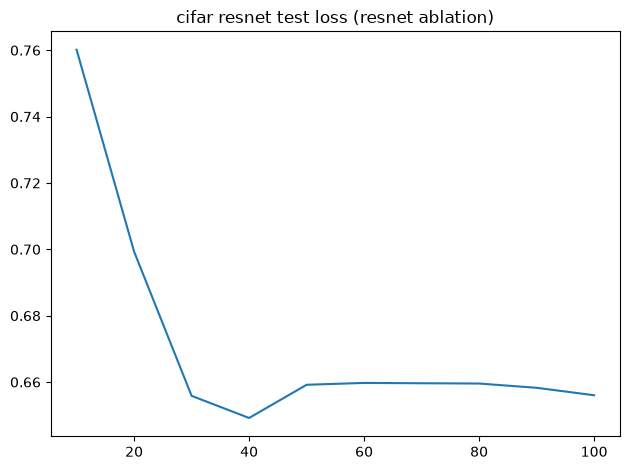

In [155]:
acc = accs[-1]
print("final test acc:", acc)
plt.plot([i * 10 for i in range(1, 11)], losses)
plt.title("cifar resnet test loss (resnet ablation)")
plt.tight_layout()
plt.savefig("figures/cifar_resnet_res_ablation_test_loss.png")
plt.show()

## Q4

In [118]:
# download pneumonia dataset
from medmnist import PneumoniaMNIST
train_dataset = PneumoniaMNIST(split="train", download=True)
val_dataset = PneumoniaMNIST(split="val", download=True)
test_dataset = PneumoniaMNIST(split="test", download=True)

In [119]:
# assemble dataset
X_train = []
y_train = []
for img, label in train_dataset:
    X_train.append(np.array(img))
    y_train.append(label[0])

X_train = np.array(X_train)
y_train = np.array(y_train)

In [120]:
# assemble dataset - val
X_val = []
y_val = []
for img, label in train_dataset:
    X_val.append(np.array(img))
    y_val.append(label[0])

X_val = np.array(X_val)
y_val = np.array(y_val)

In [121]:
# assemble dataset - test
X_test = []
y_test = []
for img, label in test_dataset:
    X_test.append(np.array(img))
    y_test.append(label[0])

X_test = np.array(X_test)
y_test = np.array(y_test)

In [72]:
# train models for each lr - auc
from ResNet.Model import Config, Cifar

for i, lr in enumerate([0.02, 0.05, 0.1]):
    tune_config = Config(save_interval=1, dataset='mnist', loss='aucm', optim='pesg', channels=1, batch_size=64, weight_decay=0, scheduler='multistep', max_epochs=15, config_id=6+i, lr=lr)
    modeler = Cifar(tune_config)
    losses = modeler.train(X_train, y_train, tune_config.max_epochs)

### Training... ###
Epoch 1 Loss 0.055840 Duration 2.899 seconds.
Checkpoint has been created.
Epoch 2 Loss 0.032355 Duration 2.949 seconds.
Checkpoint has been created.
Epoch 3 Loss 0.050352 Duration 2.855 seconds.
Checkpoint has been created.
Epoch 4 Loss 0.019507 Duration 2.790 seconds.
Checkpoint has been created.
Epoch 5 Loss 0.044260 Duration 2.806 seconds.
Checkpoint has been created.
Epoch 6 Loss 0.019339 Duration 2.731 seconds.
Checkpoint has been created.
Epoch 7 Loss 0.012381 Duration 2.744 seconds.
Checkpoint has been created.
Epoch 8 Loss 0.019287 Duration 2.719 seconds.
Checkpoint has been created.
Epoch 9 Loss 0.015414 Duration 2.786 seconds.
Checkpoint has been created.
Reducing learning rate to 0.00200 @ T=657!
Updating regularizer @ T=657!
Epoch 10 Loss 0.029966 Duration 2.830 seconds.
Checkpoint has been created.
Epoch 11 Loss 0.030249 Duration 2.782 seconds.
Checkpoint has been created.
Epoch 12 Loss 0.013352 Duration 2.759 seconds.
Checkpoint has been created.
Epoc

In [ ]:
# run validation per model - pick one w/ best accuracy
best_acc = 0
best_lr = None
for i, lr in enumerate([0.003, 0.01, 0.03]):
    tune_config = Config(save_interval=1, dataset='mnist', loss='aucm', optim='pesg', channels=1, batch_size=64, weight_decay=0, scheduler='multistep', max_epochs=15, config_id=6+i, lr=lr)
    modeler = Cifar(tune_config)
    accs, _, _, _ = modeler.test_or_validate(X_val, y_val, [15])
    acc = accs[0]
    if acc > best_acc:
        best_lr = lr
        best_acc = acc


### Test or Validation ###
Restored model parameters from checkpoints/6/model-15.ckpt
Test accuracy: 0.9514
ROC_AUC: 0.9872
PR_AUC: 0.9956
### Test or Validation ###
Restored model parameters from checkpoints/7/model-15.ckpt
Test accuracy: 0.9354
ROC_AUC: 0.9863
PR_AUC: 0.9954
### Test or Validation ###
Restored model parameters from checkpoints/8/model-15.ckpt
Test accuracy: 0.6769
ROC_AUC: 0.9831
PR_AUC: 0.9943


In [77]:
# initialize model - AUC
auc_config = Config(save_interval=1, dataset='mnist', loss='aucm', optim='pesg', channels=1, batch_size=64, weight_decay=0, scheduler='multistep', max_epochs=15, config_id=9, lr=best_lr)
modeler = Cifar(auc_config)

In [ ]:
auc_losses = modeler.train(X_train, y_train, auc_config.max_epochs)

### Training... ###
Epoch 1 Loss 0.084101 Duration 2.869 seconds.
Checkpoint has been created.
Epoch 2 Loss 0.041028 Duration 2.907 seconds.
Checkpoint has been created.
Epoch 3 Loss 0.044977 Duration 2.895 seconds.
Checkpoint has been created.
Epoch 4 Loss -0.004754 Duration 2.976 seconds.
Checkpoint has been created.
Epoch 5 Loss -0.010566 Duration 2.939 seconds.
Checkpoint has been created.
Epoch 6 Loss 0.021623 Duration 2.863 seconds.
Checkpoint has been created.
Epoch 7 Loss 0.026143 Duration 2.974 seconds.
Checkpoint has been created.
Epoch 8 Loss 0.029613 Duration 2.964 seconds.
Checkpoint has been created.
Epoch 9 Loss 0.022760 Duration 3.013 seconds.
Checkpoint has been created.
Reducing learning rate to 0.00030 @ T=657!
Updating regularizer @ T=657!
Epoch 10 Loss 0.014844 Duration 2.874 seconds.
Checkpoint has been created.
Epoch 11 Loss 0.005406 Duration 2.941 seconds.
Checkpoint has been created.
Epoch 12 Loss 0.019409 Duration 2.710 seconds.
Checkpoint has been created.
Ep

In [122]:
# get train auc curves
auc_config = Config(save_interval=1, dataset='mnist', loss='aucm', optim='pesg', channels=1, batch_size=64, weight_decay=0, scheduler='multistep', max_epochs=15, config_id=9, lr=best_lr)
modeler = Cifar(auc_config)
accs, rocs, prs, _ = modeler.test_or_validate(X_train, y_train, [i for i in range(1, 16)])

### Test or Validation ###
Restored model parameters from checkpoints/9/model-1.ckpt
Test accuracy: 0.2579
ROC_AUC: 0.8644
PR_AUC: 0.9390
Restored model parameters from checkpoints/9/model-2.ckpt
Test accuracy: 0.3944
ROC_AUC: 0.9684
PR_AUC: 0.9890
Restored model parameters from checkpoints/9/model-3.ckpt
Test accuracy: 0.2579
ROC_AUC: 0.9600
PR_AUC: 0.9848
Restored model parameters from checkpoints/9/model-4.ckpt
Test accuracy: 0.3360
ROC_AUC: 0.9468
PR_AUC: 0.9798
Restored model parameters from checkpoints/9/model-5.ckpt
Test accuracy: 0.4756
ROC_AUC: 0.9681
PR_AUC: 0.9885
Restored model parameters from checkpoints/9/model-6.ckpt
Test accuracy: 0.8585
ROC_AUC: 0.9754
PR_AUC: 0.9902
Restored model parameters from checkpoints/9/model-7.ckpt
Test accuracy: 0.7430
ROC_AUC: 0.9858
PR_AUC: 0.9952
Restored model parameters from checkpoints/9/model-8.ckpt
Test accuracy: 0.8745
ROC_AUC: 0.9650
PR_AUC: 0.9879
Restored model parameters from checkpoints/9/model-9.ckpt
Test accuracy: 0.7984
ROC_A

final acc: 0.85089209855565


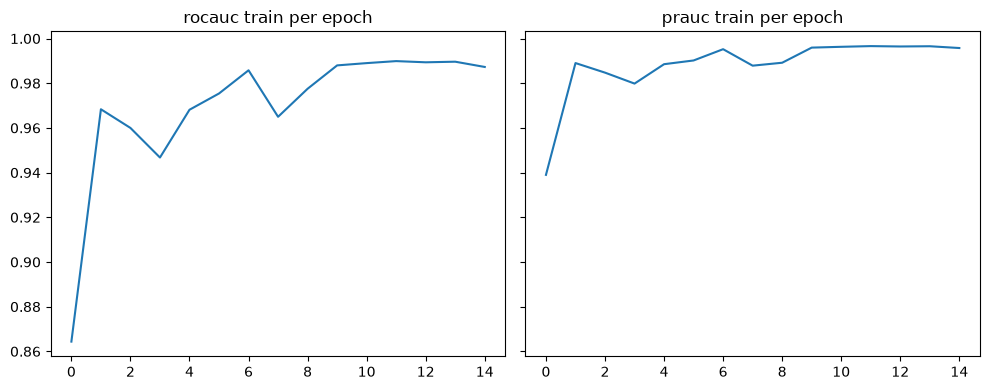

In [128]:
import matplotlib.pyplot as plt
print("final acc:", accs[-1])

fig, axes = plt.subplots(nrows=1, ncols=2, sharex=True, sharey=True, figsize=(10, 4))
axes = axes.flatten()

for i, metric in enumerate(["rocauc", "prauc"]):
    ax = axes[i]
    curve = rocs if metric == 'rocauc' else prs
    ax.plot(curve)
    ax.set_title(f"{metric} train per epoch")

plt.tight_layout()
plt.savefig("aucml_auc_curves_trian.png")
plt.show()


In [129]:
# get test auc curves
auc_config = Config(save_interval=1, dataset='mnist', loss='aucm', optim='pesg', channels=1, batch_size=64, weight_decay=0, scheduler='multistep', max_epochs=15, config_id=9, lr=best_lr)
modeler = Cifar(auc_config)
accs, rocs, prs, _ = modeler.test_or_validate(X_test, y_test, [i for i in range(1, 16)])

### Test or Validation ###
Restored model parameters from checkpoints/9/model-1.ckpt
Test accuracy: 0.3750
ROC_AUC: 0.8647
PR_AUC: 0.8957
Restored model parameters from checkpoints/9/model-2.ckpt
Test accuracy: 0.4904
ROC_AUC: 0.9146
PR_AUC: 0.9431
Restored model parameters from checkpoints/9/model-3.ckpt
Test accuracy: 0.3750
ROC_AUC: 0.9293
PR_AUC: 0.9394
Restored model parameters from checkpoints/9/model-4.ckpt
Test accuracy: 0.4327
ROC_AUC: 0.9011
PR_AUC: 0.9320
Restored model parameters from checkpoints/9/model-5.ckpt
Test accuracy: 0.5593
ROC_AUC: 0.9216
PR_AUC: 0.9515
Restored model parameters from checkpoints/9/model-6.ckpt
Test accuracy: 0.6907
ROC_AUC: 0.8874
PR_AUC: 0.9146
Restored model parameters from checkpoints/9/model-7.ckpt
Test accuracy: 0.6250
ROC_AUC: 0.9468
PR_AUC: 0.9492
Restored model parameters from checkpoints/9/model-8.ckpt
Test accuracy: 0.7212
ROC_AUC: 0.9127
PR_AUC: 0.9421
Restored model parameters from checkpoints/9/model-9.ckpt
Test accuracy: 0.6651
ROC_A

final acc: 0.8557692307692307


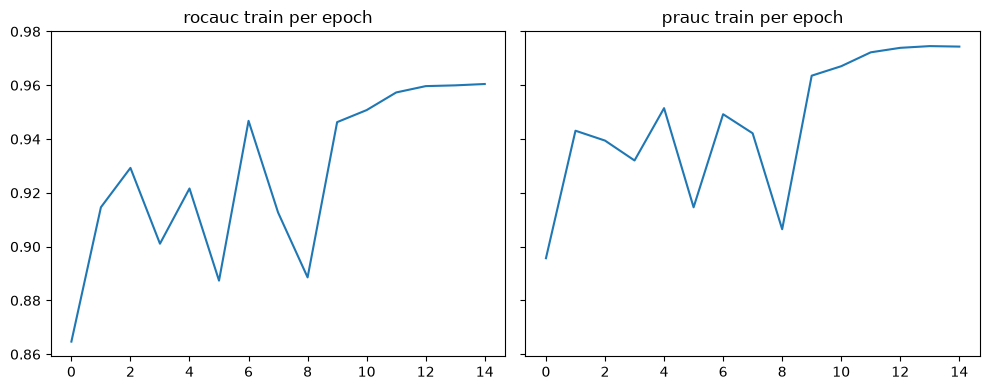

In [130]:
import matplotlib.pyplot as plt
print("final acc:", accs[-1])

fig, axes = plt.subplots(nrows=1, ncols=2, sharex=True, sharey=True, figsize=(10, 4))
axes = axes.flatten()

for i, metric in enumerate(["rocauc", "prauc"]):
    ax = axes[i]
    curve = rocs if metric == 'rocauc' else prs
    ax.plot(curve)
    ax.set_title(f"{metric} train per epoch")

plt.tight_layout()
plt.savefig("aucml_auc_curves_test.png")
plt.show()


In [80]:
# train models for each lr - ap
from ResNet.Model import Config, Cifar

for i, (lr, g) in enumerate([(lr, g) for lr in [5e-4, 1e-3, 2e-3] for g in [0.2, 0.5, 0.8]]):
    tune_config = Config(save_interval=1, dataset='mnist', loss='ap', optim='soap', channels=1, batch_size=64, weight_decay=0, scheduler='multistep', max_epochs=15, config_id=10+i, lr=lr, gamma=g)
    modeler = Cifar(tune_config)
    losses = modeler.train(X_train, y_train, tune_config.max_epochs)

### Training... ###
Epoch 1 Loss 0.000000 Duration 2.719 seconds.
Checkpoint has been created.
Epoch 2 Loss -0.021874 Duration 2.669 seconds.
Checkpoint has been created.
Epoch 3 Loss -0.015884 Duration 2.625 seconds.
Checkpoint has been created.
Epoch 4 Loss -0.009662 Duration 2.633 seconds.
Checkpoint has been created.
Epoch 5 Loss -0.009304 Duration 2.850 seconds.
Checkpoint has been created.
Epoch 6 Loss -0.008526 Duration 2.762 seconds.
Checkpoint has been created.
Epoch 7 Loss -0.004477 Duration 2.372 seconds.
Checkpoint has been created.
Epoch 8 Loss -0.002878 Duration 2.367 seconds.
Checkpoint has been created.
Epoch 9 Loss -0.003235 Duration 2.527 seconds.
Checkpoint has been created.
Epoch 10 Loss -0.002007 Duration 2.393 seconds.
Checkpoint has been created.
Epoch 11 Loss -0.000669 Duration 2.488 seconds.
Checkpoint has been created.
Epoch 12 Loss -0.001871 Duration 2.523 seconds.
Checkpoint has been created.
Epoch 13 Loss -0.001075 Duration 2.357 seconds.
Checkpoint has bee

In [81]:

# run validation per model - pick one w/ best accuracy
best_acc = 0
best_hp = None
for i, (lr, g) in enumerate([(lr, g) for lr in [5e-4, 1e-3, 2e-3] for g in [0.2, 0.5, 0.8]]):
    tune_config = Config(save_interval=1, dataset='mnist', loss='ap', optim='soap', channels=1, batch_size=64, weight_decay=0, scheduler='multistep', max_epochs=15, config_id=10+i, lr=lr, gamma=g)
    modeler = Cifar(tune_config)
    accs, _, _, _ = modeler.test_or_validate(X_val, y_val, [15])
    acc = accs[0]
    if acc > best_acc:
        best_hp = (lr, g)
        best_acc = acc


### Test or Validation ###
Restored model parameters from checkpoints/10/model-15.ckpt
Test accuracy: 0.8592
ROC_AUC: 0.9937
PR_AUC: 0.9979
### Test or Validation ###
Restored model parameters from checkpoints/11/model-15.ckpt
Test accuracy: 0.8683
ROC_AUC: 0.9945
PR_AUC: 0.9982
### Test or Validation ###
Restored model parameters from checkpoints/12/model-15.ckpt
Test accuracy: 0.8369
ROC_AUC: 0.9952
PR_AUC: 0.9984
### Test or Validation ###
Restored model parameters from checkpoints/13/model-15.ckpt
Test accuracy: 0.8607
ROC_AUC: 0.9925
PR_AUC: 0.9976
### Test or Validation ###
Restored model parameters from checkpoints/14/model-15.ckpt
Test accuracy: 0.8248
ROC_AUC: 0.9927
PR_AUC: 0.9976
### Test or Validation ###
Restored model parameters from checkpoints/15/model-15.ckpt
Test accuracy: 0.8492
ROC_AUC: 0.9932
PR_AUC: 0.9978
### Test or Validation ###
Restored model parameters from checkpoints/16/model-15.ckpt
Test accuracy: 0.8290
ROC_AUC: 0.9916
PR_AUC: 0.9972
### Test or Validati

In [85]:
# inititalize model - ap
ap_config = Config(save_interval=1, dataset='mnist', loss='ap', optim='soap', channels=1, batch_size=64, weight_decay=0, scheduler='multistep', max_epochs=15, config_id=19, lr=best_hp[0], gamma=best_hp[1])
modeler = Cifar(ap_config)

In [ ]:
ap_losses = modeler.train(X_train, y_train, ap_config.max_epochs)

### Training... ###
Epoch 1 Loss -0.000000 Duration 2.563 seconds.
Checkpoint has been created.
Epoch 2 Loss -0.004333 Duration 2.577 seconds.
Checkpoint has been created.
Epoch 3 Loss -0.007478 Duration 2.515 seconds.
Checkpoint has been created.
Epoch 4 Loss -0.005102 Duration 2.635 seconds.
Checkpoint has been created.
Epoch 5 Loss -0.002830 Duration 2.553 seconds.
Checkpoint has been created.
Epoch 6 Loss -0.001274 Duration 2.563 seconds.
Checkpoint has been created.
Epoch 7 Loss -0.001264 Duration 2.530 seconds.
Checkpoint has been created.
Epoch 8 Loss -0.002403 Duration 2.565 seconds.
Checkpoint has been created.
Epoch 9 Loss -0.001314 Duration 2.456 seconds.
Checkpoint has been created.
Epoch 10 Loss -0.001993 Duration 2.457 seconds.
Checkpoint has been created.
Epoch 11 Loss -0.001143 Duration 2.454 seconds.
Checkpoint has been created.
Epoch 12 Loss -0.001078 Duration 2.462 seconds.
Checkpoint has been created.
Epoch 13 Loss 0.001383 Duration 2.441 seconds.
Checkpoint has bee

In [133]:
# get train auc curves
ap_config = Config(save_interval=1, dataset='mnist', loss='ap', optim='soap', channels=1, batch_size=64, weight_decay=0, scheduler='multistep', max_epochs=15, config_id=19, lr=best_hp[0], gamma=best_hp[1])
modeler = Cifar(ap_config)
accs, rocs, prs, _ = modeler.test_or_validate(X_train, y_train, [i for i in range(1, 16)])

### Test or Validation ###
Restored model parameters from checkpoints/19/model-1.ckpt
Test accuracy: 0.8917
ROC_AUC: 0.9753
PR_AUC: 0.9916
Restored model parameters from checkpoints/19/model-2.ckpt
Test accuracy: 0.5204
ROC_AUC: 0.9798
PR_AUC: 0.9933
Restored model parameters from checkpoints/19/model-3.ckpt
Test accuracy: 0.7158
ROC_AUC: 0.9876
PR_AUC: 0.9959
Restored model parameters from checkpoints/19/model-4.ckpt
Test accuracy: 0.6859
ROC_AUC: 0.9876
PR_AUC: 0.9960
Restored model parameters from checkpoints/19/model-5.ckpt
Test accuracy: 0.8418
ROC_AUC: 0.9870
PR_AUC: 0.9957
Restored model parameters from checkpoints/19/model-6.ckpt
Test accuracy: 0.9010
ROC_AUC: 0.9887
PR_AUC: 0.9961
Restored model parameters from checkpoints/19/model-7.ckpt
Test accuracy: 0.6438
ROC_AUC: 0.9891
PR_AUC: 0.9964
Restored model parameters from checkpoints/19/model-8.ckpt
Test accuracy: 0.7787
ROC_AUC: 0.9917
PR_AUC: 0.9972
Restored model parameters from checkpoints/19/model-9.ckpt
Test accuracy: 0.4

final acc: 0.8513169073916738


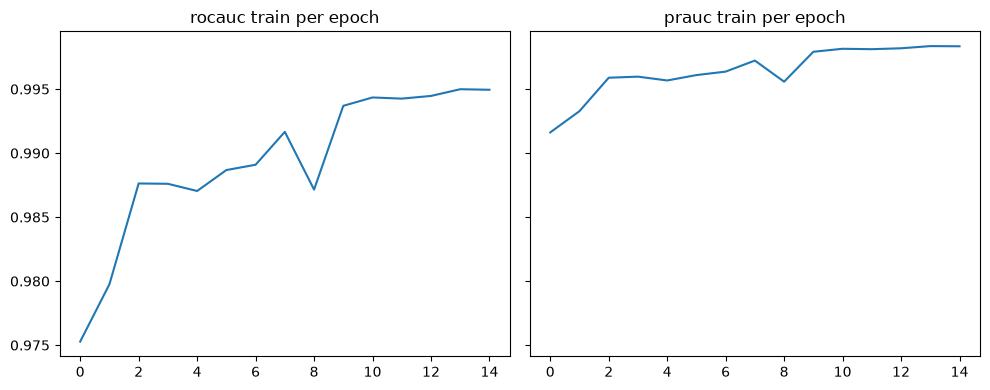

In [134]:
import matplotlib.pyplot as plt
print("final acc:", accs[-1])

fig, axes = plt.subplots(nrows=1, ncols=2, sharex=True, sharey=True, figsize=(10, 4))
axes = axes.flatten()

for i, metric in enumerate(["rocauc", "prauc"]):
    ax = axes[i]
    curve = rocs if metric == 'rocauc' else prs
    ax.plot(curve)
    ax.set_title(f"{metric} train per epoch")

plt.tight_layout()
plt.savefig("aucml_ap_curves_train.png")
plt.show()


In [135]:
# get test auc curves
ap_config = Config(save_interval=1, dataset='mnist', loss='ap', optim='soap', channels=1, batch_size=64, weight_decay=0, scheduler='multistep', max_epochs=15, config_id=19, lr=best_hp[0], gamma=best_hp[1])
modeler = Cifar(ap_config)
accs, rocs, prs, _ = modeler.test_or_validate(X_test, y_test, [i for i in range(1, 16)])

### Test or Validation ###
Restored model parameters from checkpoints/19/model-1.ckpt
Test accuracy: 0.8590
ROC_AUC: 0.9249
PR_AUC: 0.9492
Restored model parameters from checkpoints/19/model-2.ckpt
Test accuracy: 0.6074
ROC_AUC: 0.9392
PR_AUC: 0.9600
Restored model parameters from checkpoints/19/model-3.ckpt
Test accuracy: 0.7324
ROC_AUC: 0.9384
PR_AUC: 0.9574
Restored model parameters from checkpoints/19/model-4.ckpt
Test accuracy: 0.7244
ROC_AUC: 0.9568
PR_AUC: 0.9718
Restored model parameters from checkpoints/19/model-5.ckpt
Test accuracy: 0.8365
ROC_AUC: 0.9574
PR_AUC: 0.9713
Restored model parameters from checkpoints/19/model-6.ckpt
Test accuracy: 0.8878
ROC_AUC: 0.9428
PR_AUC: 0.9582
Restored model parameters from checkpoints/19/model-7.ckpt
Test accuracy: 0.7003
ROC_AUC: 0.9574
PR_AUC: 0.9731
Restored model parameters from checkpoints/19/model-8.ckpt
Test accuracy: 0.8077
ROC_AUC: 0.9623
PR_AUC: 0.9762
Restored model parameters from checkpoints/19/model-9.ckpt
Test accuracy: 0.4

final acc: 0.8637820512820513


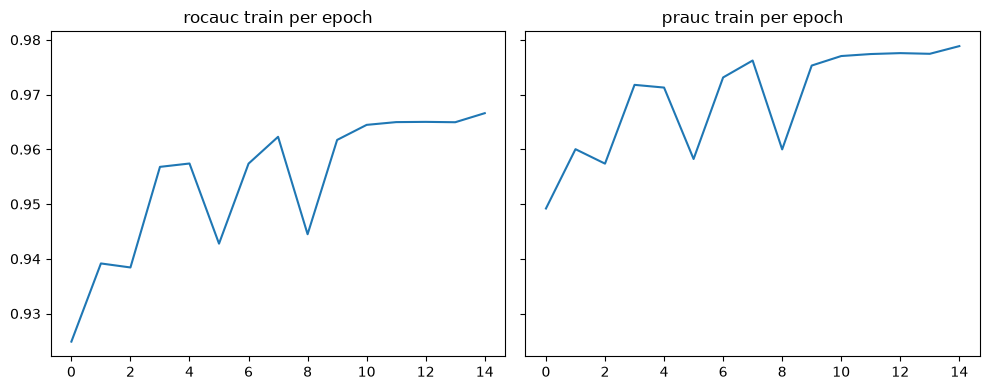

In [136]:
import matplotlib.pyplot as plt
print("final acc:", accs[-1])

fig, axes = plt.subplots(nrows=1, ncols=2, sharex=True, sharey=True, figsize=(10, 4))
axes = axes.flatten()

for i, metric in enumerate(["rocauc", "prauc"]):
    ax = axes[i]
    curve = rocs if metric == 'rocauc' else prs
    ax.plot(curve)
    ax.set_title(f"{metric} train per epoch")

plt.tight_layout()
plt.savefig("aucml_ap_curves_test.png")
plt.show()


In [87]:
# initialize model - CE

for i, lr in enumerate([5e-4, 1e-3, 2e-3]):
    tune_config = Config(save_interval=1, dataset='mnist', loss='ce', num_classes=2, channels=1, batch_size=64, weight_decay=0, scheduler='multistep', max_epochs=15, lr=lr, config_id=20+i)
    modeler = Cifar(tune_config)
    losses = modeler.train(X_train, y_train, tune_config.max_epochs)

### Training... ###
Epoch 1 Loss 0.159007 Duration 2.165 seconds.
Checkpoint has been created.
Epoch 2 Loss 0.130807 Duration 2.126 seconds.
Checkpoint has been created.
Epoch 3 Loss 0.125765 Duration 2.111 seconds.
Checkpoint has been created.
Epoch 4 Loss 0.031049 Duration 2.103 seconds.
Checkpoint has been created.
Epoch 5 Loss 0.099080 Duration 2.117 seconds.
Checkpoint has been created.
Epoch 6 Loss 0.191142 Duration 2.103 seconds.
Checkpoint has been created.
Epoch 7 Loss 0.181384 Duration 2.105 seconds.
Checkpoint has been created.
Epoch 8 Loss 0.094315 Duration 2.117 seconds.
Checkpoint has been created.
Epoch 9 Loss 0.065845 Duration 2.207 seconds.
Checkpoint has been created.
Epoch 10 Loss 0.051155 Duration 2.112 seconds.
Checkpoint has been created.
Epoch 11 Loss 0.203344 Duration 2.119 seconds.
Checkpoint has been created.
Epoch 12 Loss 0.035507 Duration 2.116 seconds.
Checkpoint has been created.
Epoch 13 Loss 0.101234 Duration 2.119 seconds.
Checkpoint has been created.
E

In [88]:

# run validation per model - pick one w/ best accuracy
best_acc = 0
best_lr = None
for i, lr in enumerate([5e-4, 1e-3, 2e-3]):
    tune_config = Config(save_interval=1, dataset='mnist', loss='ce', num_classes=2, channels=1, batch_size=64, weight_decay=0, scheduler='multistep', max_epochs=15, lr=lr, config_id=20+i)
    modeler = Cifar(tune_config)
    accs, _, _, _ = modeler.test_or_validate(X_val, y_val, [15])
    acc = accs[0]
    if acc > best_acc:
        best_hp = lr
        best_acc = acc


### Test or Validation ###
Restored model parameters from checkpoints/20/model-15.ckpt


/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:209: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  y_proba = F.softmax(y_proba)[:, 1]


Test accuracy: 0.9760
ROC_AUC: 0.9979
PR_AUC: 0.9993
### Test or Validation ###
Restored model parameters from checkpoints/21/model-15.ckpt


/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:209: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  y_proba = F.softmax(y_proba)[:, 1]


Test accuracy: 0.9456
ROC_AUC: 0.9974
PR_AUC: 0.9991
### Test or Validation ###
Restored model parameters from checkpoints/22/model-15.ckpt
Test accuracy: 0.9505
ROC_AUC: 0.9967
PR_AUC: 0.9989


/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:209: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  y_proba = F.softmax(y_proba)[:, 1]


In [90]:
# inititliaze model - ce
ce_config = Config(save_interval=1, dataset='mnist', loss='ce', num_classes=2, channels=1, batch_size=64, weight_decay=0, scheduler='multistep', max_epochs=15, lr=lr, config_id=23)
modeler = Cifar(ce_config)

In [ ]:
ce_losses = modeler.train(X_train, y_train, ce_config.max_epochs)

### Training... ###
Epoch 1 Loss 0.174999 Duration 2.215 seconds.
Checkpoint has been created.
Epoch 2 Loss 0.112834 Duration 2.150 seconds.
Checkpoint has been created.
Epoch 3 Loss 0.095295 Duration 2.182 seconds.
Checkpoint has been created.
Epoch 4 Loss 0.087212 Duration 2.187 seconds.
Checkpoint has been created.
Epoch 5 Loss 0.023068 Duration 2.229 seconds.
Checkpoint has been created.
Epoch 6 Loss 0.090868 Duration 2.453 seconds.
Checkpoint has been created.
Epoch 7 Loss 0.087099 Duration 2.194 seconds.
Checkpoint has been created.
Epoch 8 Loss 0.070575 Duration 2.202 seconds.
Checkpoint has been created.
Epoch 9 Loss 0.038747 Duration 2.126 seconds.
Checkpoint has been created.
Epoch 10 Loss 0.043598 Duration 2.103 seconds.
Checkpoint has been created.
Epoch 11 Loss 0.116799 Duration 2.123 seconds.
Checkpoint has been created.
Epoch 12 Loss 0.038064 Duration 2.104 seconds.
Checkpoint has been created.
Epoch 13 Loss 0.194213 Duration 2.288 seconds.
Checkpoint has been created.
E

In [137]:
# get train auc curves
ce_config = Config(save_interval=1, dataset='mnist', loss='ce', num_classes=2, channels=1, batch_size=64, weight_decay=0, scheduler='multistep', max_epochs=15, lr=lr, config_id=23)
modeler = Cifar(ce_config)
accs, rocs, prs, _ = modeler.test_or_validate(X_train, y_train, [i for i in range(1, 16)])

### Test or Validation ###
Restored model parameters from checkpoints/23/model-1.ckpt


/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:209: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  elif self.config.loss == 'ce':


Test accuracy: 0.6508
ROC_AUC: 0.9646
PR_AUC: 0.9866
Restored model parameters from checkpoints/23/model-2.ckpt


/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:209: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  elif self.config.loss == 'ce':


Test accuracy: 0.8953
ROC_AUC: 0.9871
PR_AUC: 0.9956
Restored model parameters from checkpoints/23/model-3.ckpt


/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:209: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  elif self.config.loss == 'ce':


... (20 outputs left out)

Test accuracy: 0.9594
ROC_AUC: 0.9972
PR_AUC: 0.9990
Restored model parameters from checkpoints/23/model-14.ckpt


/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:209: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  elif self.config.loss == 'ce':


Test accuracy: 0.9641
ROC_AUC: 0.9976
PR_AUC: 0.9992
Restored model parameters from checkpoints/23/model-15.ckpt
Test accuracy: 0.9269
ROC_AUC: 0.9973
PR_AUC: 0.9991


/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:209: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  elif self.config.loss == 'ce':


final acc: 0.9269328802039083


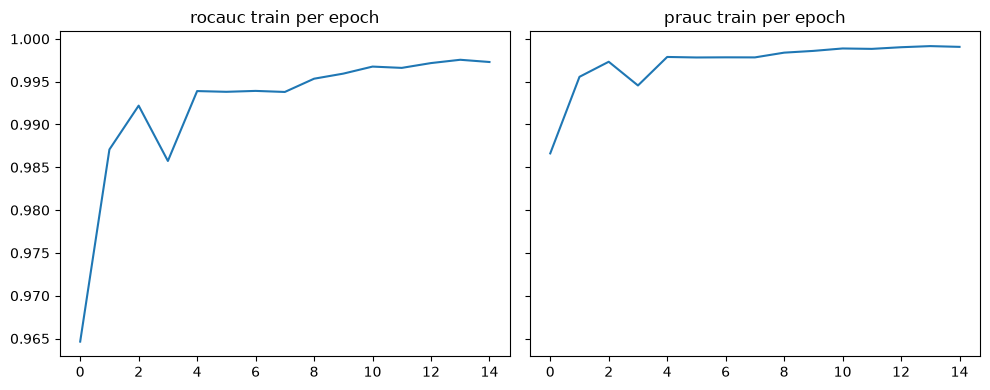

In [138]:
import matplotlib.pyplot as plt
print("final acc:", accs[-1])

fig, axes = plt.subplots(nrows=1, ncols=2, sharex=True, sharey=True, figsize=(10, 4))
axes = axes.flatten()

for i, metric in enumerate(["rocauc", "prauc"]):
    ax = axes[i]
    curve = rocs if metric == 'rocauc' else prs
    ax.plot(curve)
    ax.set_title(f"{metric} train per epoch")

plt.tight_layout()
plt.savefig("aucml_ce_curves_train.png")
plt.show()


In [139]:
# get test auc curves
ce_config = Config(save_interval=1, dataset='mnist', loss='ce', num_classes=2, channels=1, batch_size=64, weight_decay=0, scheduler='multistep', max_epochs=15, lr=lr, config_id=23)
modeler = Cifar(ce_config)
accs, rocs, prs, _ = modeler.test_or_validate(X_test, y_test, [i for i in range(1, 16)])

### Test or Validation ###
Restored model parameters from checkpoints/23/model-1.ckpt
Test accuracy: 0.6843
ROC_AUC: 0.9074
PR_AUC: 0.9331
Restored model parameters from checkpoints/23/model-2.ckpt


/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:209: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  elif self.config.loss == 'ce':
/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:209: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  elif self.config.loss == 'ce':
/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:209: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  elif self.config.loss == 'ce':


Test accuracy: 0.7083
ROC_AUC: 0.9460
PR_AUC: 0.9608
Restored model parameters from checkpoints/23/model-3.ckpt
Test accuracy: 0.9038
ROC_AUC: 0.9547
PR_AUC: 0.9660
Restored model parameters from checkpoints/23/model-4.ckpt
Test accuracy: 0.8686
ROC_AUC: 0.9339
PR_AUC: 0.9527


/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:209: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  elif self.config.loss == 'ce':
/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:209: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  elif self.config.loss == 'ce':
/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:209: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  elif self.config.loss == 'ce':


Restored model parameters from checkpoints/23/model-5.ckpt
Test accuracy: 0.8670
ROC_AUC: 0.9609
PR_AUC: 0.9739
Restored model parameters from checkpoints/23/model-6.ckpt
Test accuracy: 0.8494
ROC_AUC: 0.9544
PR_AUC: 0.9663
Restored model parameters from checkpoints/23/model-7.ckpt


/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:209: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  elif self.config.loss == 'ce':
/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:209: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  elif self.config.loss == 'ce':


... (2 outputs left out)

Test accuracy: 0.9295
ROC_AUC: 0.9666
PR_AUC: 0.9766
Restored model parameters from checkpoints/23/model-10.ckpt
Test accuracy: 0.9279
ROC_AUC: 0.9738
PR_AUC: 0.9826
Restored model parameters from checkpoints/23/model-11.ckpt


/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:209: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  elif self.config.loss == 'ce':
/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:209: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  elif self.config.loss == 'ce':
/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:209: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  elif self.config.loss == 'ce':


Test accuracy: 0.9295
ROC_AUC: 0.9755
PR_AUC: 0.9838
Restored model parameters from checkpoints/23/model-12.ckpt
Test accuracy: 0.9359
ROC_AUC: 0.9767
PR_AUC: 0.9850
Restored model parameters from checkpoints/23/model-13.ckpt
Test accuracy: 0.9359
ROC_AUC: 0.9784
PR_AUC: 0.9862
Restored model parameters from checkpoints/23/model-14.ckpt
Test accuracy: 0.9263
ROC_AUC: 0.9762
PR_AUC: 0.9848
Restored model parameters from checkpoints/23/model-15.ckpt
Test accuracy: 0.9311
ROC_AUC: 0.9779
PR_AUC: 0.9862


/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:209: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  elif self.config.loss == 'ce':
/Users/tahaismail/Desktop/School/MASTERS/Fall 2026/CS_633/hw/Fall26ML-HW4/ResNet/Model.py:209: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  elif self.config.loss == 'ce':


final acc: 0.9310897435897436


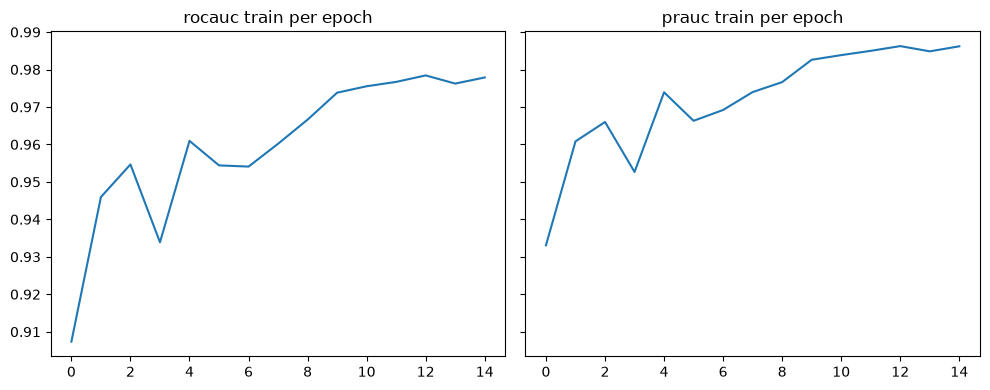

In [140]:
import matplotlib.pyplot as plt
print("final acc:", accs[-1])

fig, axes = plt.subplots(nrows=1, ncols=2, sharex=True, sharey=True, figsize=(10, 4))
axes = axes.flatten()

for i, metric in enumerate(["rocauc", "prauc"]):
    ax = axes[i]
    curve = rocs if metric == 'rocauc' else prs
    ax.plot(curve)
    ax.set_title(f"{metric} train per epoch")

plt.tight_layout()
plt.savefig("aucml_ce_curves_test.png")
plt.show()
